*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Learn about Obi-Wan Kenobi 🌌

Are you a Star Wars fan? If not, this exercise will teach you a lot about one of the most important characters of the saga, Obi-Wan Kenobi. We analyse the French Wikipedia article about him: word clouds first, then TF-IDF to find the words that characterize each paragraph, and the cosine similarity to find paragraphs that talk about the same thing.

The text is in French, but you don't need to read French: the word clouds and the numbers will speak for you.

## The data 📜

`data/obi_wan_kenobi_fr.txt` contains the text of the article, **one paragraph per line**.

*Source: Wikipedia, article « Obi-Wan Kenobi », [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).*

The file was made by downloading the page and keeping the text of its paragraphs (the `<p>` tags of the HTML), with code like this one (you don't need to run it):

```python
import requests
from bs4 import BeautifulSoup

html = requests.get("https://fr.wikipedia.org/wiki/Obi-Wan_Kenobi").text
soup = BeautifulSoup(html, "html.parser")
paragraphs = [p.text.strip() for p in soup.find_all("p") if p.text.strip()]
```

Let's import the libraries and load the paragraphs.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import plotly.express as px
import spacy
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from spacy.lang.fr.stop_words import STOP_WORDS
from wordcloud import WordCloud

import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"
course_colors = ListedColormap(["#3B47C4", "#E4572E", "#2E7D4F", "#8E7CC3", "#4BA3C3"])

with open("data/obi_wan_kenobi_fr.txt", encoding="utf-8") as file:
    paragraphs = file.read().splitlines()

## Explore the text 🔎

1. How many paragraphs are there? Print the first one. How many words (separated by spaces) do the paragraphs contain: the minimum, the mean and the maximum?

In [ ]:
print(f"{len(paragraphs)} paragraphs\n")
print(paragraphs[0], "\n")
n_words = pd.Series([len(p.split()) for p in paragraphs])
print(f"Words per paragraph: min {n_words.min()}, mean {n_words.mean():.0f}, max {n_words.max()}")

77 paragraphs

Obi-Wan Kenobi, également dit Ben Kenobi, est un personnage de fiction dans l'univers de la série cinématographique Star Wars, créée par George Lucas. Il est un chevalier et maître Jedi, personnage emblématique de la saga. Il fut, jusqu'à la sortie de Rogue One en 2016, l'un des seuls personnages à faire son apparition dans chaque film, que ce soit en présence réelle, en forme de « fantôme », ou même simplement en caméo où l'on n'entend que sa voix. 

Words per paragraph: min 18, mean 56, max 190


2. Load spaCy's small French model, `fr_core_news_sm`, in a variable `nlp`. Process all the paragraphs with `nlp.pipe` and store the result in a list `docs`. Then display the `text`, `lemma_`, `pos_` and `is_stop` of the first 30 tokens of the first paragraph. What happens to "Obi-Wan", to "l'univers", to the verbs?

💡 Hint: `nlp.pipe(paragraphs)` returns a generator: wrap it in `list(...)` to keep the documents. A slice of a `Doc`, like `docs[0][:30]`, gives its first tokens.

In [ ]:
nlp = spacy.load("fr_core_news_sm")
docs = list(nlp.pipe(paragraphs))

pd.DataFrame([(t.text, t.lemma_, t.pos_, t.is_stop) for t in docs[0][:30]],
             columns=["text", "lemma_", "pos_", "is_stop"])

,text,lemma_,pos_,is_stop
0,Obi,obi,NOUN,False
1,-,-,PROPN,False
2,Wan,Wan,PROPN,False
3,Kenobi,Kenobi,PROPN,False
4,",",",",PUNCT,False
5,également,également,ADV,True
6,dit,dire,VERB,True
7,Ben,Ben,PROPN,False
8,Kenobi,Kenobi,PROPN,False
9,",",",",PUNCT,False


**"Obi-Wan" is cut into three tokens: "Obi", "-" and "Wan". "l'univers" becomes "l'" (lemma "le", a stop word) and "univers". The verbs get their infinitive as lemma: "est" → "être", "dit" → "dire", "créée" → "créer". The French model knows French grammar.**

## Word clouds ☁️

3. Make a word cloud of the whole article (all the paragraphs joined in one string). Pass `stopwords=set()` to see the raw text. What do you notice?

💡 Hint: `WordCloud(stopwords=set(), random_state=0).generate(text)` makes the cloud; show it with `plt.imshow(cloud)` and hide the axes with `plt.axis("off")`. Add `background_color="white"` and `colormap=course_colors` if you want.

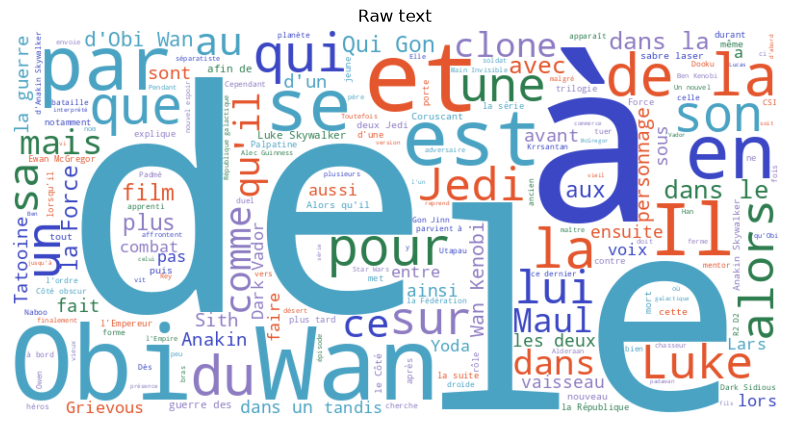

In [ ]:
def show_cloud(text, title, stopwords=None):
    cloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords,
                      colormap=course_colors, random_state=0).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(cloud, interpolation="bilinear")
    plt.title(title)
    plt.axis("off")
    plt.show()

full_text = " ".join(paragraphs)
show_cloud(full_text, "Raw text", stopwords=set())

**The biggest words are French stop words ("de", "la", "le", "et", "les", "à"…): they are the most frequent words of any French text, so they hide everything else. Only "Obi", "Wan" and "Jedi" manage to appear among them.**

4. How many French stop words does spaCy know? Print 15 of them (sorted). Then make the word cloud again, with spaCy's French stop words. What changes?

507 French stop words, for example: ['a', 'abord', 'afin', 'ah', 'ai', 'aie', 'ainsi', 'ait', 'allaient', 'allons', 'alors', 'anterieur', 'anterieure', 'anterieures', 'antérieur']


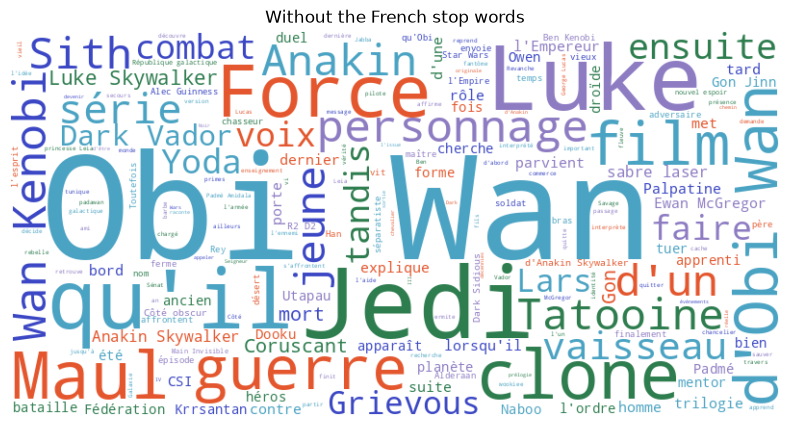

In [ ]:
print(f"{len(STOP_WORDS)} French stop words, for example: {sorted(STOP_WORDS)[:15]}")
show_cloud(full_text, "Without the French stop words", stopwords=STOP_WORDS)

**The stop words are gone and the characters appear: Obi, Wan, Luke, Anakin, Jedi, Maul. But some stop words survive when they are glued to the next word by an apostrophe ("qu'il", "d'un", "d'Obi"): `WordCloud` cuts the text on spaces and keeps the apostrophes, so "qu'il" is not in the list. And the forms of a word are still counted apart. We need a real French tokenizer and lemmatizer: spaCy.**

5. Write a function `clean_text(doc, stop_words)` that returns the lemmas of a spaCy `Doc` in lower case, keeping only the tokens made of letters that are not stop words. Apply it to every paragraph and store the result in a list `clean_paragraphs`. Print the first cleaned paragraph, then make the word cloud of the lemmas. What is better than in the previous cloud? Can you spot a mistake of the lemmatizer?

💡 Hint: test both `token.is_stop` and `token.lemma_.lower() not in stop_words`, so that the function also works with your own stop words later.

obi wan kenobi ben kenobi personnage fiction univers série cinématographique star wars créer george lucas chevalier maître jedi personnage emblématique saga sortie rogue one personnage faire apparition film présence réel forme fantôme simplement caméo entendre voix


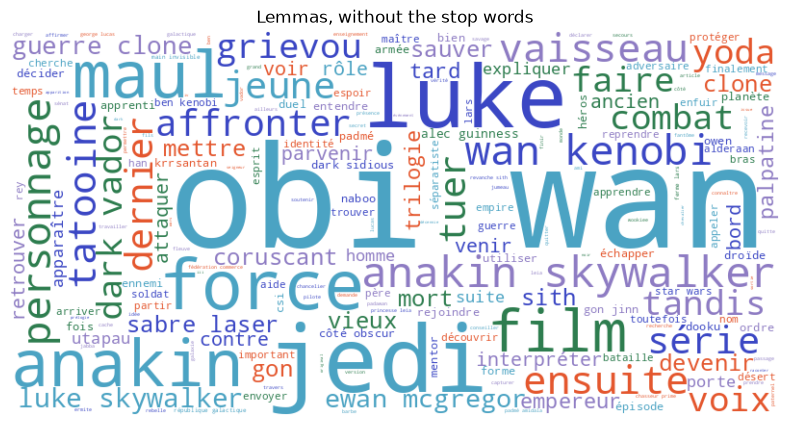

In [ ]:
def clean_text(doc, stop_words=STOP_WORDS):
    lemmas = []
    for token in doc:
        lemma = token.lemma_.lower()
        if token.is_alpha and not token.is_stop and lemma not in stop_words:
            lemmas.append(lemma)
    return " ".join(lemmas)

clean_paragraphs = [clean_text(doc) for doc in docs]
print(clean_paragraphs[0])
show_cloud(" ".join(clean_paragraphs), "Lemmas, without the stop words")

**spaCy separates the elisions ("qu'" + "il", "d'" + "un"), so these stop words are now removed, and the lemmas merge the forms of each word. The lemmatizer is not perfect: it sometimes turns "Grievous", the name of a general, into "grievou", as if the final "s" were a plural. Lemmatizers are trained on common words, and they struggle with proper nouns.**

6. Which are the 20 most frequent lemmas of the article? Show them in a bar chart. Which of them do not teach us anything about Obi-Wan Kenobi?

💡 Hint: split every cleaned paragraph into words, put all the words in a `pd.Series` and use `.value_counts()`.

In [ ]:
all_lemmas = pd.Series(" ".join(clean_paragraphs).split())
lemma_counts = all_lemmas.value_counts()
print(f"{len(all_lemmas)} lemmas in total, {len(lemma_counts)} different ones")

fig = px.bar(lemma_counts.head(20), title="The 20 most frequent lemmas of the article")
fig.update_layout(xaxis_title="lemma", yaxis_title="occurrences", showlegend=False)
fig.show()

2321 lemmas in total, 1001 different ones


**"obi" and "wan" are by far the most frequent lemmas (114 times each, out of 2,321 lemmas): in an article about Obi-Wan, his name is everywhere, so it says nothing new. "kenobi" belongs to the same name. General words like "personnage" ("character") or "ensuite" ("then") also tell little about the subject.**

7. Add "obi", "wan", "kenobi" and a few uninformative words of your choice to the stop words, clean the paragraphs again with this new list, and make a new word cloud. What do you see now?

💡 Hint: `STOP_WORDS | {"obi", "wan"}` is the union of two sets.

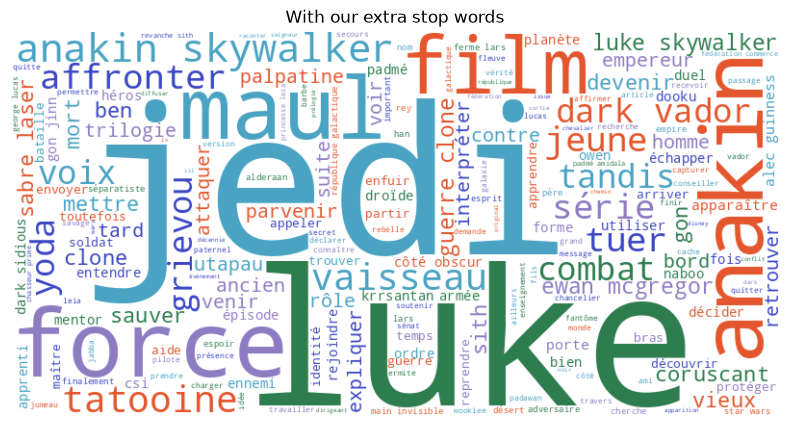

In [ ]:
extra_stop_words = {"obi", "wan", "kenobi", "personnage", "ensuite", "faire", "dernier"}
my_stop_words = STOP_WORDS | extra_stop_words
clean_paragraphs_extra = [clean_text(doc, my_stop_words) for doc in docs]
show_cloud(" ".join(clean_paragraphs_extra), "With our extra stop words")

**Without the name of the hero, the cloud tells his story: the Jedi and the Force, his apprentices Anakin and Luke Skywalker, his enemies Maul and Dark Vador, the films. Choosing the stop words is a manual, subjective step. In the next part, TF-IDF will do part of this work automatically.**

## TF-IDF 🍍

For the rest of the exercise, we use `clean_paragraphs` (spaCy's stop words only, **without** our extra ones), to see what TF-IDF does with the name of the hero.

8. First, let's make a common mistake: treat the whole article as **one single document**. Fit a `TfidfVectorizer` on a list that contains only the joined text of all the cleaned paragraphs, and look at the different values of `idf_`. What do you notice? Why? What do the tf-idf weights reduce to?

💡 Hint: `np.unique(vectorizer.idf_)` lists the different values.

In [ ]:
one_document = [" ".join(clean_paragraphs)]
vectorizer_one = TfidfVectorizer()
X_one = vectorizer_one.fit_transform(one_document)
print("Shape:", X_one.shape)
print("Different values of the idf:", np.unique(vectorizer_one.idf_))

Shape: (1, 998)
Different values of the idf: [1.]


**There is only one value: every word has an idf of 1. With one document ($n = 1$), every word of the vocabulary is in this document ($\text{df} = 1$), so $\text{idf} = \ln\frac{1+1}{1+1} + 1 = 1$ for all the words. The idf cannot tell rare words from common words anymore, and the "tf-idf" is just the word counts divided by a constant (the L2 norm): the same information as a word count. The idf only makes sense when the corpus has several documents: here, each paragraph is a natural document.**

9. Now treat **each paragraph as a document**. Fit a `TfidfVectorizer` on `clean_paragraphs`, and print the shape of the matrix. Build a DataFrame with, for each word, its document frequency (the number of paragraphs that contain it) and its idf. Show the 10 words with the smallest idf. What is the idf of "obi", "jedi" and "utapau"?

💡 Hint: `vectorizer.get_feature_names_out()` gives the words in the order of the columns. The document frequency is the number of non-zero values in each column: `(X > 0).sum(axis=0)`, then `np.asarray(...).ravel()` to get a flat array.

In [ ]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(clean_paragraphs)
words = vectorizer.get_feature_names_out()
print(f"{X.shape[0]} documents (paragraphs), {X.shape[1]} words in the vocabulary\n")

idf_table = pd.DataFrame({
    "document frequency": np.asarray((X > 0).sum(axis=0)).ravel(),
    "idf": vectorizer.idf_,
}, index=words)
print(idf_table.sort_values("idf").head(10).round(3), "\n")
print(idf_table.loc[["obi", "jedi", "utapau"]].round(3))
print(f"\nLargest idf (words in a single paragraph): {idf_table.idf.max():.3f}")

77 documents (paragraphs), 998 words in the vocabulary

           document frequency    idf
wan                        67  1.137
obi                        67  1.137
jedi                       30  1.923
skywalker                  21  2.266
anakin                     21  2.266
luke                       19  2.361
force                      15  2.584
kenobi                     13  2.718
dark                       13  2.718
guerre                     11  2.872 

        document frequency    idf
obi                     67  1.137
jedi                    30  1.923
utapau                   2  4.258

Largest idf (words in a single paragraph): 4.664


**Now the idf varies. "obi" and "wan" are in 67 of the 77 paragraphs: they get the smallest idf, 1.137. "jedi" is in 30 paragraphs (idf 1.923), and "utapau", a planet named in only 2 paragraphs, gets 4.258. A word found in a single paragraph gets the maximum, 4.664. TF-IDF lowers the weight of the hero's name automatically, without any manual list.**

10. Compare two rankings of the words: the 15 most frequent words (total number of occurrences, with a `CountVectorizer`) and the 15 words with the highest **mean tf-idf** over the paragraphs. Show them side by side. Which words go down, which words go up?

In [ ]:
counts = CountVectorizer().fit_transform(clean_paragraphs)   # same vocabulary as the TfidfVectorizer
ranking = pd.DataFrame({
    "occurrences": np.asarray(counts.sum(axis=0)).ravel(),
    "mean tf-idf": np.asarray(X.mean(axis=0)).ravel(),
}, index=words)
ranking["rank by occurrences"] = ranking["occurrences"].rank(ascending=False, method="min").astype(int)
ranking["rank by tf-idf"] = ranking["mean tf-idf"].rank(ascending=False, method="min").astype(int)

top_count = ranking.sort_values("occurrences", ascending=False).head(15)
top_tfidf = ranking.sort_values("mean tf-idf", ascending=False).head(15)
pd.DataFrame({
    "top by occurrences": top_count.index,
    "occurrences": top_count["occurrences"].to_numpy(),
    "top by mean tf-idf": top_tfidf.index,
    "mean tf-idf": top_tfidf["mean tf-idf"].round(4).to_numpy(),
})

,top by occurrences,occurrences,top by mean tf-idf,mean tf-idf
0,wan,114,wan,0.0729
1,obi,114,obi,0.0729
2,luke,37,luke,0.0461
3,jedi,34,jedi,0.0400
4,anakin,27,anakin,0.0392
5,skywalker,21,skywalker,0.0302
6,force,17,clone,0.0302
7,kenobi,16,force,0.0273
8,dark,15,kenobi,0.0238
9,maul,15,guerre,0.0230


In [ ]:
print("Words in the top 15 by occurrences only:", sorted(set(top_count.index) - set(top_tfidf.index)))
print("Words in the top 15 by tf-idf only:     ", sorted(set(top_tfidf.index) - set(top_count.index)))
print(f"\nShare of the occurrences of 'obi': {ranking.loc['obi', 'occurrences'] / ranking['occurrences'].sum():.1%}")
print(f"Share of the total tf-idf of 'obi': {ranking.loc['obi', 'mean tf-idf'] / ranking['mean tf-idf'].sum():.1%}")

Words in the top 15 by occurrences only: ['personnage']
Words in the top 15 by tf-idf only:      ['tatooine']

Share of the occurrences of 'obi': 4.9%
Share of the total tf-idf of 'obi': 1.5%


**The two lists are close: "obi" and "wan" stay at the top, because they are in almost every paragraph, and a low idf (1.137) does not cancel such high counts. But their weight is cut: "obi" makes 4.9% of all the occurrences, but only 1.5% of the total tf-idf. The words concentrated in a few paragraphs go up: "clone" moves from 11th to 7th, "guerre" ("war") from 14th to 10th, and "tatooine" enters the top 15. "personnage" ("character"), a general word spread over the whole article, leaves it.**

11. `max_df` removes the words present in too many documents. Fit a `TfidfVectorizer(max_df=0.5)` on the cleaned paragraphs: which words disappear from the vocabulary?

In [ ]:
vectorizer_max = TfidfVectorizer(max_df=0.5).fit(clean_paragraphs)
print("Removed by max_df=0.5:", sorted(set(words) - set(vectorizer_max.get_feature_names_out())))

Removed by max_df=0.5: ['obi', 'wan']


**Only "obi" and "wan" are removed: they are the only words present in more than half of the paragraphs (67 out of 77). `max_df` finds the "stop words of the corpus" for us, the ones we added by hand in question 7.**

## Similar paragraphs 📐

12. Compute the cosine similarity between all the pairs of paragraphs (a 77 × 77 matrix) and show it as a heatmap. Which two different paragraphs are the most similar? Print them, and find the words that contribute the most to their similarity.

💡 Hint: set the diagonal to 0 with `np.fill_diagonal` (each paragraph is identical to itself), then `np.unravel_index(similarity.argmax(), similarity.shape)` gives the row and the column of the maximum. The TF-IDF rows have a length of 1, so the cosine is the sum of the products of the weights: the largest products are the words that contribute the most.

In [ ]:
similarity = cosine_similarity(X)
fig = px.imshow(similarity, color_continuous_scale="Blues", zmin=0, zmax=1,
                title="Cosine similarity between the 77 paragraphs")
fig.update_layout(xaxis_title="paragraph", yaxis_title="paragraph")
fig.show()

np.fill_diagonal(similarity, 0)
i, j = np.unravel_index(similarity.argmax(), similarity.shape)
print(f"Most similar paragraphs: {i} and {j}, cosine similarity = {similarity[i, j]:.3f}\n")
print(f"[{i}]", paragraphs[i], "\n")
print(f"[{j}]", paragraphs[j], "\n")

tfidf_table = pd.DataFrame(X.toarray(), columns=words)
products = (tfidf_table.loc[i] * tfidf_table.loc[j]).sort_values(ascending=False)
print("Largest contributions:")
print(products.head(5).round(3))

Most similar paragraphs: 25 and 27, cosine similarity = 0.352

[25] Obi-Wan se rend à Utapau, à la recherche de Grievous. L'administrateur de Pau City, Tion Medon, lui confirme la présence de Grievous. Comme l'armée séparatiste occupe Utapau depuis son arrivée bien que cette planète souhaite rester neutre durant la guerre, Tion soutient l'offensive républicaine guidée par Obi-Wan afin de chasser d'Utapau la CSI. 

[27] Bien que la mission à Utapau semble être une victoire pour Obi-Wan, le commandant Cody, dirigeant de l'armée clone ayant suivi Obi-Wan à Utapau, reçoit l'ordre de Dark Sidious de trahir les Jedi, désormais considérés comme des ennemis de la République. Obi-Wan échappe à l'ordre 66 en tombant dans un cratère de la planète. Il quitte alors Utapau à bord du vaisseau de Grievous, le Sans-âme, pour se rendre à Coruscant. 

Largest contributions:
utapau      0.249
grievous    0.021
bien        0.019
planète     0.019
armée       0.019
dtype: float64


**Paragraphs 25 and 27 (similarity 0.352) both tell Obi-Wan's mission on the planet Utapau, where he hunts General Grievous. "utapau" alone brings 0.249 of the 0.352: it appears 3 times in each paragraph and in no other paragraph, so it has a high tf and the highest possible idf for a shared word. The other shared words (grievous, planète, armée…) add a little each. Note "bien" (from "bien que", "although"): a word that should be a stop word, which slipped through the cleaning.**

13. **Bonus: a tiny search engine.** Write a question as a short French text, for example `"combat au sabre laser contre Dark Maul"`. Clean it with the same function, turn it into a TF-IDF vector with the **fitted** vectorizer, and print the 3 paragraphs with the highest cosine similarity to it.

💡 Hint: use `vectorizer.transform([...])`, not `fit_transform`: the query must be described with the vocabulary and the idf learned on the article.

In [ ]:
query = "combat au sabre laser contre Dark Maul"
query_vector = vectorizer.transform([clean_text(nlp(query))])
scores = cosine_similarity(query_vector, X).ravel()
for k in scores.argsort()[::-1][:3]:
    print(f"[{k}] similarity {scores[k]:.3f}: {paragraphs[k][:250]}…\n")

[39] similarity 0.267: En 2 av. BY, Obi-Wan/Ben, devenu vieux, fait la rencontre d'Ezra Bridger sur Tatooine. Ce dernier, accompagné du droïde Chopper, est venu lui demander de rejoindre la Rébellion et l'informer que son vieil ennemi, Dark Maul, le cherche aussi. Le Zabra…

[7] similarity 0.235: Alors qu'à Coruscant, Palpatine, qui cache son identité de Dark Sidious, est élu pour diriger le Sénat, les deux Jedi repartent à Naboo, où ils affrontent le mystérieux apprenti Sith Dark Maul. Obi-Wan voit Qui-Gon se faire tuer par Maul, mais le ven…

[44] similarity 0.212: Pendant le trajet jusqu'à Alderaan, Obi-Wan entraîne le jeune Luke aux techniques du sabre laser et à l'utilisation de la Force, pour user du sabre laser, plus intuitivement. Arrivés à proximité de la planète, ils constatent avec horreur que cette de…



**The three best paragraphs are about Maul or the lightsaber: paragraph 39 (Maul is looking for Obi-Wan on Tatooine, 0.267), paragraph 7 (the fight against Dark Maul on Naboo, 0.235) and paragraph 44 (Obi-Wan teaches Luke the lightsaber, 0.212). The search engine does not understand French: it only matches the lemmas of the query with the rare words of the paragraphs. Real search engines started with exactly this idea.**